install the required libraries

In [2]:
!pip install --upgrade pip
!pip install pykan
!pip install yfinance pandas numpy
!pip install pyarrow

Download the S&P company list 

In [11]:
import pandas as pd
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Create a browser request
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0 Safari/537.36"
}

response = requests.get(url, headers=headers, timeout=30)

# Check whether the request worked
response.raise_for_status()

# Read the tables from Wikipedia
tables = pd.read_html(StringIO(response.text))

# Extract the first table
sp500 = tables[0]

# Display first 10 companies
display(sp500.head(10))

# Count companies
print("Number of companies:", len(sp500))

sp500.to_csv("sp500_company_list.csv", index=False)

print("Company list saved successfully!")

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999


Number of companies: 503
Company list saved successfully!


In [12]:
tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

print("Number of tickers:", len(tickers))
print(tickers[:10])

Number of tickers: 503
['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [55]:
import yfinance as yf
import os
import time

# Create folder for downloaded data
os.makedirs("stock_data", exist_ok=True)

# Download in batches of 50
batch_size = 50

for i in range(0, len(tickers), batch_size):

    batch = tickers[i:i + batch_size]

    print("Downloading batch:", i // batch_size + 1)

    data = yf.download(
        tickers=batch,
        start="2021-01-01",
        end="2025-01-01",
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="ticker",
        threads=True,
        progress=False
    )

    # Save each batch
    data.to_parquet(
        f"stock_data/batch_{i // batch_size + 1}.parquet"
    )

    time.sleep(2)

print("Download process finished!")

$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$DOW: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)

2 Failed downloads:
['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
['DOW']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)


$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$GE: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)

2 Failed downloads:
['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
['GE']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)


$MRVL: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)

1 Failed download:
['MRVL']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)


$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$TPR: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)
$STX: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)

3 Failed downloads:
['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
['TPR', 'STX']: possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01)


$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Download process finished!


In [56]:
import yfinance as yf

failed_tickers = ["FDXF", "HONA", "Q", "SNDK", "VYLR"]

for ticker in failed_tickers:

    print("\nChecking:", ticker)

    data = yf.download(
        ticker,
        start="2021-01-01",
        end="2025-01-01",
        auto_adjust=False,
        progress=False
    )

    if data.empty:
        print("No historical data available.")
    else:
        print("Data available!")
        print("First date:", data.index.min())
        print("Last date:", data.index.max())
        print("Number of records:", len(data))


Checking: FDXF


$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: HONA


$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: Q


$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


No historical data available.

Checking: SNDK
No historical data available.

Checking: VYLR
No historical data available.


In [97]:
import pandas as pd

excluded = pd.DataFrame({
    "Ticker": ["FDXF", "HONA", "Q", "SNDK", "VYLR"],
    "Reason": [
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance",
        "No historical data available from Yahoo Finance"
    ]
})

excluded.to_csv("excluded_tickers.csv", index=False)
display(excluded)

,Ticker,Reason
0,FDXF,No historical data available from Yahoo Finance
1,HONA,No historical data available from Yahoo Finance
2,Q,No historical data available from Yahoo Finance
3,SNDK,No historical data available from Yahoo Finance
4,VYLR,No historical data available from Yahoo Finance


In [98]:
import glob
import os

files = glob.glob("stock_data/*.parquet")

print("Number of saved batch files:", len(files))

for file in files:
    print(os.path.basename(file),
          round(os.path.getsize(file) / 1024, 2), "KB")

Number of saved batch files: 11
batch_1.parquet 2181.84 KB
batch_10.parquet 2099.93 KB
batch_11.parquet 141.67 KB
batch_2.parquet 2188.88 KB
batch_3.parquet 2170.76 KB
batch_4.parquet 2085.97 KB
batch_5.parquet 1992.09 KB
batch_6.parquet 2159.09 KB
batch_7.parquet 2140.88 KB
batch_8.parquet 2083.81 KB
batch_9.parquet 2032.76 KB


In [99]:
import pandas as pd
import glob
import os

files = sorted(glob.glob("stock_data/*.parquet"))

# Open the first batch
sample = pd.read_parquet(files[0])

print("File inspected:", os.path.basename(files[0]))
print("\nData dimensions:")
print(sample.shape)

print("\nFirst five rows:")
display(sample.head())

print("\nColumn structure:")
print(sample.columns)

File inspected: batch_1.parquet

Data dimensions:
(1005, 400)

First five rows:


Ticker             AMP                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  195.300003  195.899994  185.800003  188.110001  171.959763   
2021-01-05  188.110001  189.850006  185.710007  187.009995  170.954208   
2021-01-06  191.259995  199.940002  190.830002  197.740005  180.763031   
2021-01-07  200.000000  202.179993  199.410004  200.130005  182.947769   
2021-01-08  200.750000  201.639999  198.520004  201.550003  184.245865   

Ticker                                           AMZN              ...  \
Price       Volume Dividends Stock Splits        Open        High  ...   
Date                                                               ...   
2021-01-04  587800       0.0          0.0  163.500000  163.600006  ...   
2021-01-05  560900       0.0          0.0  158.300507  161.169006  ...   
2021-01-06  736400       0.0          0.0  157.324005  159.875504  ...   
2021-01-07  585900       0.0          0.0  157.850006  160.427002  ...   
2021-01-08  545400       0.0          0.0  159.000000  159.531998  ...   

Ticker           AEP                     APTV                          \
Price      Dividends Stock Splits        Open        High         Low   
Date                                                                    
2021-01-04       0.0          0.0  131.360001  131.970001  127.760002   
2021-01-05       0.0          0.0  129.000000  133.800003  129.000000   
2021-01-06       0.0          0.0  133.740005  138.960007  133.009995   
2021-01-07       0.0          0.0  141.020004  145.850006  140.610001   
2021-01-08       0.0          0.0  146.270004  151.190002  143.809998   

Ticker                                                              
Price            Close   Adj Close   Volume Dividends Stock Splits  
Date                                                                
2021-01-04  129.509995  129.509995  1934500       0.0          0.0  
2021-01-05  133.389999  133.389999  1762800       0.0          0.0  
2021-01-06  138.110001  138.110001  2078600       0.0          0.0  
2021-01-07  144.800003  144.800003  2237100       0.0          0.0  
2021-01-08  145.559998  145.559998  2471800       0.0          0.0  

[5 rows x 400 columns]


Column structure:
MultiIndex([( 'AMP',         'Open'),
            ( 'AMP',         'High'),
            ( 'AMP',          'Low'),
            ( 'AMP',        'Close'),
            ( 'AMP',    'Adj Close'),
            ( 'AMP',       'Volume'),
            ( 'AMP',    'Dividends'),
            ( 'AMP', 'Stock Splits'),
            ('AMZN',         'Open'),
            ('AMZN',         'High'),
            ...
            ( 'AEP',    'Dividends'),
            ( 'AEP', 'Stock Splits'),
            ('APTV',         'Open'),
            ('APTV',         'High'),
            ('APTV',          'Low'),
            ('APTV',        'Close'),
            ('APTV',    'Adj Close'),
            ('APTV',       'Volume'),
            ('APTV',    'Dividends'),
            ('APTV', 'Stock Splits')],
           names=['Ticker', 'Price'], length=400)


Combine all 11 batches 

In [100]:
import pandas as pd
import glob
import os

# Find all batch files and sort them numerically
files = glob.glob("stock_data/batch_*.parquet")
files = sorted(files, key=lambda x: int(
    os.path.basename(x).replace("batch_", "").replace(".parquet", "")
))

# Read all batches
batch_data = []

for file in files:
    data = pd.read_parquet(file)
    batch_data.append(data)
    print(os.path.basename(file), data.shape)

# Combine all companies into one dataset
all_stocks = pd.concat(batch_data, axis=1)

# Sort dates
all_stocks = all_stocks.sort_index()

# Save the combined dataset
all_stocks.to_parquet("all_stocks_combined.parquet")

print("\nCombined dataset dimensions:", all_stocks.shape)
print("First date:", all_stocks.index.min())
print("Last date:", all_stocks.index.max())
print("Number of unique tickers:",
      all_stocks.columns.get_level_values("Ticker").nunique())

batch_1.parquet (1005, 400)
batch_2.parquet (1005, 400)
batch_3.parquet (1005, 400)
batch_4.parquet (1005, 396)
batch_5.parquet (1005, 396)
batch_6.parquet (1005, 400)
batch_7.parquet (1005, 398)
batch_8.parquet (1005, 398)
batch_9.parquet (1005, 394)
batch_10.parquet (1005, 398)
batch_11.parquet (1005, 24)

Combined dataset dimensions: (1005, 4004)
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00
Number of unique tickers: 503


# Check historical data coverage 

In [101]:
# Get all unique company tickers
tickers_in_data = all_stocks.columns.get_level_values("Ticker").unique()

coverage = []

for ticker in tickers_in_data:

    # Get this company's data
    company_data = all_stocks[ticker]

    # Count available closing prices and volume observations
    close_count = company_data["Close"].notna().sum()
    volume_count = company_data["Volume"].notna().sum()

    # Find first and last available closing-price dates
    valid_dates = company_data.index[company_data["Close"].notna()]

    first_date = valid_dates.min() if len(valid_dates) > 0 else None
    last_date = valid_dates.max() if len(valid_dates) > 0 else None

    coverage.append({
        "Ticker": ticker,
        "Close observations": close_count,
        "Volume observations": volume_count,
        "First available date": first_date,
        "Last available date": last_date
    })

coverage_df = pd.DataFrame(coverage)

# Show companies with the fewest closing-price observations
coverage_df = coverage_df.sort_values("Close observations")

display(coverage_df.head(20))

print("\nTotal companies:", len(coverage_df))
print("Companies with no closing prices:",
      (coverage_df["Close observations"] == 0).sum())

,Ticker,Close observations,Volume observations,First available date,Last available date
449,STX,0,0,NaT,NaT
448,TPR,0,0,NaT,NaT
443,SNDK,0,0,NaT,NaT
199,DOW,0,0,NaT,NaT
232,HONA,0,0,NaT,NaT
249,GE,0,0,NaT,NaT
349,MRVL,0,0,NaT,NaT
359,Q,0,0,NaT,NaT
489,VYLR,0,0,NaT,NaT
155,FDXF,0,0,NaT,NaT



Total companies: 503
Companies with no closing prices: 10


# Identify Companies with full period data 

In [102]:
# Expected number of trading dates in the downloaded dataset
expected_days = len(all_stocks.index)

# Add a percentage coverage column
coverage_df["Coverage %"] = (
    coverage_df["Close observations"] / expected_days * 100
).round(2)

# Identify companies with data on every trading date
coverage_df["Full history"] = (
    coverage_df["Close observations"] == expected_days
)

# Summarise the results
print("Expected trading dates:", expected_days)

print("Companies with full history:",
      coverage_df["Full history"].sum())

print("Companies without full history:",
      (~coverage_df["Full history"]).sum())

print("\nCompanies with full history:")
display(
    coverage_df[coverage_df["Full history"]]
    .sort_values("Ticker")
)

print("\nCompanies without full history:")
display(
    coverage_df[~coverage_df["Full history"]]
    .sort_values("Close observations")
)

Expected trading dates: 1005
Companies with full history: 483
Companies without full history: 20

Companies with full history:


,Ticker,Close observations,Volume observations,First available date,Last available date,Coverage %,Full history
42,A,1005,1005,2021-01-04,2024-12-31,100.0,True
39,AAPL,1005,1005,2021-01-04,2024-12-31,100.0,True
40,ABBV,1005,1005,2021-01-04,2024-12-31,100.0,True
15,ABNB,1005,1005,2021-01-04,2024-12-31,100.0,True
26,ABT,1005,1005,2021-01-04,2024-12-31,100.0,True
...,...,...,...,...,...,...,...
53,XYZ,1005,1005,2021-01-04,2024-12-31,100.0,True
468,YUM,1005,1005,2021-01-04,2024-12-31,100.0,True
500,ZBH,1005,1005,2021-01-04,2024-12-31,100.0,True
502,ZBRA,1005,1005,2021-01-04,2024-12-31,100.0,True



Companies without full history:


,Ticker,Close observations,Volume observations,First available date,Last available date,Coverage %,Full history
449,STX,0,0,NaT,NaT,0.00,False
448,TPR,0,0,NaT,NaT,0.00,False
443,SNDK,0,0,NaT,NaT,0.00,False
199,DOW,0,0,NaT,NaT,0.00,False
232,HONA,0,0,NaT,NaT,0.00,False
249,GE,0,0,NaT,NaT,0.00,False
349,MRVL,0,0,NaT,NaT,0.00,False
359,Q,0,0,NaT,NaT,0.00,False
489,VYLR,0,0,NaT,NaT,0.00,False
155,FDXF,0,0,NaT,NaT,0.00,False


In [103]:
coverage_df.to_csv("stock_data_coverage_report.csv", index=False)

print("Coverage report saved successfully.")

Coverage report saved successfully.


# Creating clean Dataset 

In [104]:
# Get the tickers with complete historical data
eligible_tickers = coverage_df.loc[
    coverage_df["Full history"], "Ticker"
].tolist()

# Keep only these companies in the combined dataset
clean_stocks = all_stocks.loc[
    :, all_stocks.columns.get_level_values("Ticker").isin(eligible_tickers)
].copy()

# Save the clean dataset
clean_stocks.to_parquet("clean_stocks_488.parquet")

# Save the list of included companies
pd.DataFrame({"Ticker": eligible_tickers}).to_csv(
    "included_tickers.csv", index=False
)

# Save the list of excluded companies
coverage_df.loc[
    ~coverage_df["Full history"]
].to_csv("excluded_tickers_full_report.csv", index=False)

print("Clean dataset dimensions:", clean_stocks.shape)
print("Number of included companies:",
      clean_stocks.columns.get_level_values("Ticker").nunique())
print("First date:", clean_stocks.index.min())
print("Last date:", clean_stocks.index.max())

Clean dataset dimensions: (1005, 3864)
Number of included companies: 483
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


Download the S&P 500 benchmark

In [105]:
import yfinance as yf

benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    progress=False
)

print("Benchmark dimensions:", benchmark.shape)
print("First date:", benchmark.index.min())
print("Last date:", benchmark.index.max())

display(benchmark.head())
benchmark.to_parquet("sp500_benchmark.parquet")
print("Benchmark saved successfully.")
print(benchmark.columns)

Benchmark dimensions: (1005, 8)
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,,,
2021-01-04,3700.649902,3700.649902,0.0,3769.989990,3662.709961,3764.610107,0.0,5015000000
2021-01-05,3726.860107,3726.860107,0.0,3737.830078,3695.070068,3698.020020,0.0,4591020000
2021-01-06,3748.139893,3748.139893,0.0,3783.040039,3705.340088,3712.199951,0.0,6064110000
2021-01-07,3803.790039,3803.790039,0.0,3811.550049,3764.709961,3764.709961,0.0,5099160000
2021-01-08,3824.679932,3824.679932,0.0,3826.689941,3783.600098,3815.050049,0.0,4773040000


Benchmark saved successfully.
MultiIndex([(   'Adj Close', '^GSPC'),
            (       'Close', '^GSPC'),
            (   'Dividends', '^GSPC'),
            (        'High', '^GSPC'),
            (         'Low', '^GSPC'),
            (        'Open', '^GSPC'),
            ('Stock Splits', '^GSPC'),
            (      'Volume', '^GSPC')],
           names=['Price', 'Ticker'])


# Extract adjusted closing pricess 

In [106]:
# Extract adjusted closing prices for all 488 companies
stock_adj = clean_stocks.xs(
    "Adj Close",
    axis=1,
    level="Price"
)

# Extract adjusted closing price for the S&P 500
benchmark_adj = benchmark.xs(
    "Adj Close",
    axis=1,
    level="Price"
).iloc[:, 0]

print("Stock prices shape:", stock_adj.shape)
print("Benchmark prices shape:", benchmark_adj.shape)

display(stock_adj.head())
display(benchmark_adj.head())

#Convert daily prices into weekly prices
# Get the last available adjusted closing price in each Friday-ending week
weekly_stock_prices = stock_adj.resample("W-FRI").last()
weekly_benchmark_prices = benchmark_adj.resample("W-FRI").last()

# drop final incomplete week
weekly_stock_prices = weekly_stock_prices.loc[:"2024-12-27"]
weekly_benchmark_prices = weekly_benchmark_prices.loc[:"2024-12-27"]

print("Weekly stock prices:", weekly_stock_prices.shape)
print("Weekly benchmark prices:", weekly_benchmark_prices.shape)

display(weekly_stock_prices.head())
display(weekly_benchmark_prices.head())

# Calculate weekly percentage returns
weekly_stock_returns = weekly_stock_prices.pct_change()
weekly_benchmark_returns = weekly_benchmark_prices.pct_change()

# Remove the first week because it has no previous week for comparison
weekly_stock_returns = weekly_stock_returns.dropna()
weekly_benchmark_returns = weekly_benchmark_returns.dropna()

print("Weekly stock returns:", weekly_stock_returns.shape)
print("Weekly benchmark returns:", weekly_benchmark_returns.shape)

display(weekly_stock_returns.head())
display(weekly_benchmark_returns.head())

#Calculate mean weekly return and beta
# Create a results table
risk_return = pd.DataFrame(index=weekly_stock_returns.columns)


# Arithmetic mean of weekly returns
risk_return["Mean_Weekly_Return"] = (
    weekly_stock_returns.mean()
)

# Calculate beta for each company
market_variance = weekly_benchmark_returns.var()

for ticker in weekly_stock_returns.columns:

    covariance = weekly_stock_returns[ticker].cov(
        weekly_benchmark_returns
    )

    risk_return.loc[ticker, "Beta"] = (
        covariance / market_variance
    )

# Display results
risk_return.index.name = "Ticker"

print("Risk-return dataset dimensions:", risk_return.shape)

display(risk_return.head(10))

# Save results
risk_return.to_csv("risk_return_features.csv")
print("Risk-return features saved successfully.")

Stock prices shape: (1005, 483)
Benchmark prices shape: (1005,)


Ticker,AMP,AMZN,AMGN,ALL,ANET,T,MMM,AJG,AMCR,AMD,...,WY,WDAY,VICI,WEC,XEL,VTRS,WSM,ZBH,ZTS,ZBRA
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,171.959763,159.331497,188.669937,94.200180,17.697500,15.163256,117.366707,112.987877,43.004169,92.300003,...,26.124491,228.080002,18.036827,73.924606,54.757385,14.805828,46.168064,141.603333,152.952011,378.130005
2021-01-05,170.954208,160.925507,189.585526,93.459320,17.875626,15.070549,117.168663,112.236130,43.306480,92.769997,...,26.371326,225.360001,18.270975,73.687401,54.223648,14.454449,46.710701,144.053421,154.017899,380.570007
2021-01-06,180.763031,156.919006,194.155365,95.864883,17.866875,15.364128,118.950989,114.575951,44.515739,90.330002,...,26.506689,220.000000,18.314884,74.619865,55.424549,14.765897,47.943943,148.158386,156.280518,394.820007
2021-01-07,182.947769,158.108002,194.796310,95.934608,18.498125,15.405334,115.898483,114.951820,44.137829,95.160004,...,26.761482,226.210007,18.219759,72.190598,54.340405,14.789851,48.679394,147.280060,156.140259,409.100006
2021-01-08,184.245865,159.134995,198.517120,95.830025,19.132500,15.299091,113.781563,113.561096,43.457642,94.580002,...,26.578346,227.649994,18.783178,71.937035,54.840778,14.614164,48.383423,146.956528,157.178070,405.470001


Date
2021-01-04    3700.649902
2021-01-05    3726.860107
2021-01-06    3748.139893
2021-01-07    3803.790039
2021-01-08    3824.679932
Name: ^GSPC, dtype: float64

Weekly stock prices: (208, 483)
Weekly benchmark prices: (208,)


Ticker,AMP,AMZN,AMGN,ALL,ANET,T,MMM,AJG,AMCR,AMD,...,WY,WDAY,VICI,WEC,XEL,VTRS,WSM,ZBH,ZTS,ZBRA
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,184.245865,159.134995,198.517120,95.830025,19.132500,15.299091,113.781563,113.561096,43.457642,94.580002,...,26.578346,227.649994,18.783178,71.937035,54.840778,14.614164,48.383423,146.956528,157.178070,405.470001
2021-01-15,190.398056,155.212494,204.343857,94.479057,19.816875,15.378170,113.050873,109.106972,41.757122,88.209999,...,25.893581,222.559998,18.410011,72.542313,54.173615,13.615930,55.993637,148.038177,151.054062,409.220001
2021-01-22,193.606644,164.611496,211.011292,96.248375,19.450624,15.251643,115.434143,110.732628,41.908276,92.790001,...,26.442984,235.529999,19.310017,71.470818,54.006828,13.919395,59.584770,148.861023,152.945587,408.839996
2021-01-29,180.881790,160.309998,200.964310,93.415741,19.222500,15.093485,119.954811,108.449196,41.341438,85.639999,...,24.834593,227.529999,18.497816,72.714058,53.364674,13.568019,58.053711,142.074844,144.442947,387.829987
2021-02-05,192.939377,167.607498,196.710846,93.189140,20.119375,15.251643,122.242447,111.258881,43.344265,87.900002,...,27.390512,263.950012,19.719784,71.012779,52.906002,14.294728,57.977169,147.825546,149.153091,407.109985


Date
2021-01-08    3824.679932
2021-01-15    3768.250000
2021-01-22    3841.469971
2021-01-29    3714.239990
2021-02-05    3886.830078
Freq: W-FRI, Name: ^GSPC, dtype: float64

... (2 outputs left out)

Date
2021-01-15   -0.014754
2021-01-22    0.019431
2021-01-29   -0.033120
2021-02-05    0.046467
2021-02-12    0.012349
Freq: W-FRI, Name: ^GSPC, dtype: float64

Risk-return dataset dimensions: (483, 2)


,Mean_Weekly_Return,Beta
Ticker,,
AMP,0.005768,1.278280
AMZN,0.002681,1.386667
AMGN,0.001596,0.475610
ALL,0.003865,0.518458
ANET,0.010310,1.419564
T,0.001998,0.367530
MMM,0.001142,0.869079
AJG,0.004805,0.725573
AMCR,0.000332,0.671180


Risk-return features saved successfully.


# Run a quality check on risk return Dataset 

In [107]:
import numpy as np
import pandas as pd

print("Missing values:")
print(risk_return.isna().sum())

print("\nSummary statistics:")
display(risk_return.describe())

print("\nCompanies with missing values:")
display(risk_return[risk_return.isna().any(axis=1)])

# Get the latest 60 trading dates
latest_60_dates = clean_stocks.index[-60:]

# Identify the final observation date
observation_date = clean_stocks.index.max()

print("Observation date:", observation_date)
print("First date in latest 60 sessions:", latest_60_dates[0])
print("Last date in latest 60 sessions:", latest_60_dates[-1])
print("Number of sessions:", len(latest_60_dates))

rfm_results = []

for ticker in eligible_tickers:

    # Extract daily data for this company
    company = clean_stocks[ticker]

    close = company["Close"]
    volume = company["Volume"]

    # Average volume over the preceding 20 sessions
    previous_20_average = (
        volume.shift(1).rolling(window=20).mean()
    )

    # Identify unusually high-volume days
    high_volume_days = volume > (2 * previous_20_average)

    # RECENCY: latest qualifying high-volume date
    qualifying_dates = volume.index[high_volume_days.fillna(False)]

    if len(qualifying_dates) > 0:
        latest_high_volume_date = qualifying_dates.max()

        recency = (
            observation_date - latest_high_volume_date
        ).days
    else:
        recency = np.nan

    # FREQUENCY: number of qualifying days in latest 60 sessions
    frequency = high_volume_days.loc[latest_60_dates].sum()

    # MONETARY: sum of Close multiplied by Volume
    monetary = (
        close.loc[latest_60_dates] *
        volume.loc[latest_60_dates]
    ).sum()

    # Store results
    rfm_results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary
    })

# Create RFM dataset
rfm = pd.DataFrame(rfm_results).set_index("Ticker")

print("RFM dataset dimensions:", rfm.shape)
display(rfm.head(10))

rfm.to_csv("rfm_features.csv")
print("RFM dataset saved successfully.")

Missing values:
Mean_Weekly_Return    0
Beta                  0
dtype: int64

Summary statistics:


,Mean_Weekly_Return,Beta
count,483.000000,483.000000
mean,0.002842,0.970997
std,0.002644,0.406090
min,-0.004468,0.055453
25%,0.001182,0.666316
50%,0.002615,0.944085
75%,0.004188,1.174425
max,0.017772,3.778560



Companies with missing values:


,Mean_Weekly_Return,Beta
Ticker,,


Observation date: 2024-12-31 00:00:00
First date in latest 60 sessions: 2024-10-07 00:00:00
Last date in latest 60 sessions: 2024-12-31 00:00:00
Number of sessions: 60
RFM dataset dimensions: (483, 3)


,Recency,Frequency,Monetary
Ticker,,,
VICI,11,4,8.883842e+09
WDAY,11,5,5.170406e+10
WY,11,3,6.340870e+09
VMRK,11,2,6.378171e+09
UHS,12,1,8.958052e+09
VRSN,11,2,7.259616e+09
WRB,11,2,5.864965e+09
WELL,11,3,2.105086e+10
TWLO,11,4,1.520773e+10


RFM dataset saved successfully.


Validate RFM results 

In [108]:
print("Missing values:")
print(rfm.isna().sum())

print("\nRFM summary statistics:")
display(rfm.describe())

print("\nNegative values:")
print((rfm < 0).sum())

print("\nCompanies with missing RFM values:")
display(rfm[rfm.isna().any(axis=1)])

print("\nFrequency range:")
print(rfm["Frequency"].min(), "to", rfm["Frequency"].max())

print("\nRecency range:")
print(rfm["Recency"].min(), "to", rfm["Recency"].max())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

RFM summary statistics:


,Recency,Frequency,Monetary
count,483.000000,483.000000,4.830000e+02
mean,20.420290,2.973085,3.934467e+10
std,21.388119,1.325344,1.295249e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.015831e+10
50%,11.000000,3.000000,1.665860e+10
75%,14.500000,4.000000,3.190812e+10
max,222.000000,8.000000,1.847697e+12



Negative values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Companies with missing RFM values:


,Recency,Frequency,Monetary
Ticker,,,



Frequency range:
0 to 8

Recency range:
4 to 222


Prepare the Dataset for the clustering 

In [138]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# --------------------------------
# A. Prepare risk-return dataset
# --------------------------------

risk_return_clean = risk_return.copy()

risk_scaler = StandardScaler()

risk_scaled_array = risk_scaler.fit_transform(
    risk_return_clean
)

risk_scaled = pd.DataFrame(
    risk_scaled_array,
    index=risk_return_clean.index,
    columns=risk_return_clean.columns
)

# --------------------------------
# B. Prepare RFM dataset
# --------------------------------

rfm_clean = rfm.copy()

# Log transformation of Monetary
rfm_clean["Monetary_log"] = np.log1p(
    rfm_clean["Monetary"]
)

# Use Recency, Frequency and transformed Monetary
rfm_features = rfm_clean[
    ["Recency", "Frequency", "Monetary_log"]
]

# Standardise all three features
rfm_scaler = StandardScaler()

rfm_scaled_array = rfm_scaler.fit_transform(
    rfm_features
)

rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    index=rfm_features.index,
    columns=rfm_features.columns
)

print("Risk-return scaled shape:", risk_scaled.shape)
print("RFM scaled shape:", rfm_scaled.shape)

print("\nRisk-return scaled data:")
display(risk_scaled.head())

print("\nRFM scaled data:")
display(rfm_scaled.head())

risk_scaled.to_csv("risk_return_scaled.csv")
rfm_scaled.to_csv("rfm_scaled.csv")

print("Both scaled datasets saved successfully.")

Risk-return scaled shape: (483, 2)
RFM scaled shape: (483, 3)

Risk-return scaled data:


,Mean_Weekly_Return,Beta
Ticker,,
AMP,1.107415,0.757472
AMZN,-0.061064,1.024652
AMGN,-0.471917,-1.221160
ALL,0.387125,-1.115539
ANET,2.827108,1.105745



RFM scaled data:


,Recency,Frequency,Monetary_log
Ticker,,,
AMP,-0.440902,-0.734975,-0.270247
AMZN,-0.440902,1.530936,3.411261
AMGN,-0.440902,0.775633,1.115749
ALL,0.729184,0.020329,-0.100987
ANET,1.524841,0.020329,0.965428


Both scaled datasets saved successfully.


# Hierarchical clustering 
Risk return Dataset

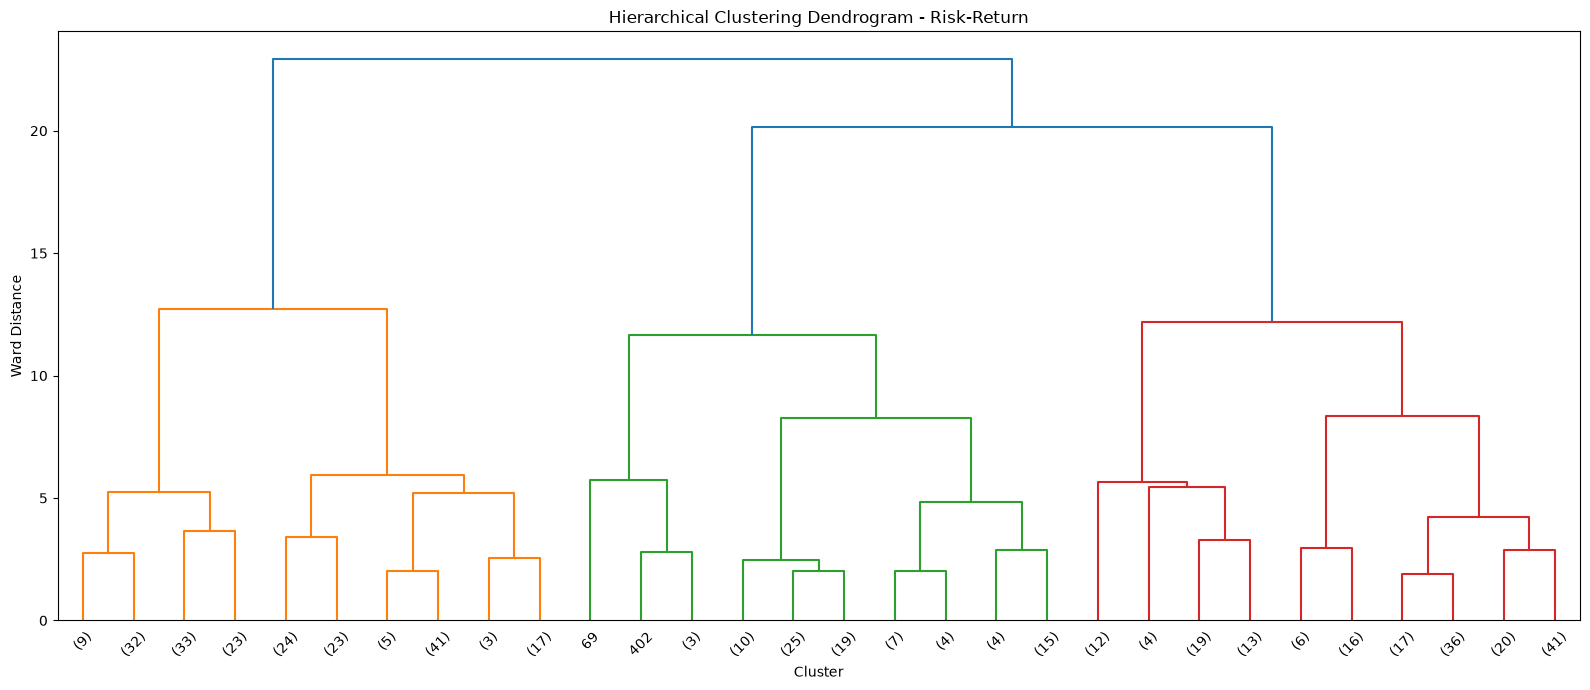

In [139]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

risk_linkage = linkage(
    risk_scaled,
    method="ward",
    metric="euclidean"
)

# Plot a readable dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    risk_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - Risk-Return")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

RFM

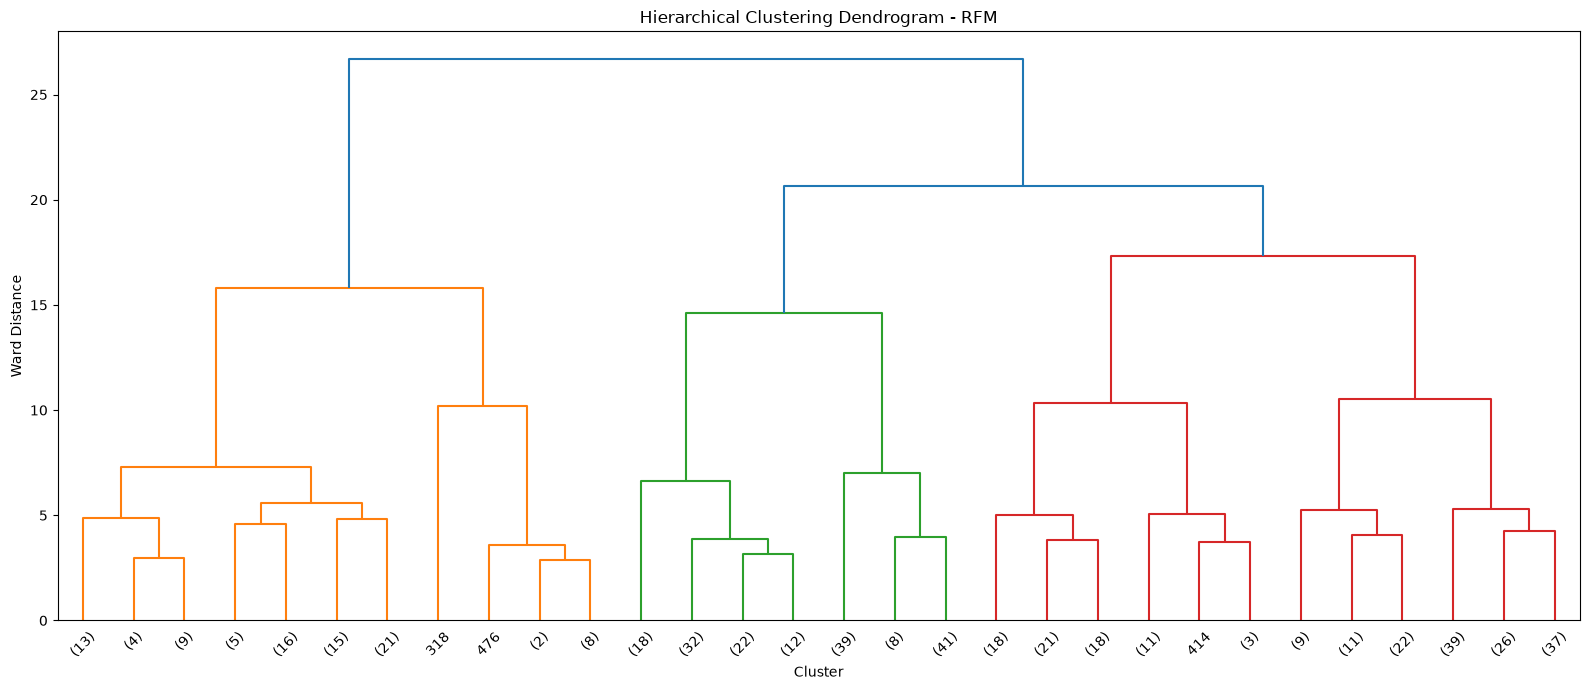

In [141]:
rfm_linkage = linkage(
    rfm_scaled,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(16, 7))

dendrogram(
    rfm_linkage,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram - RFM")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

Test different number of clusters 

In [142]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

risk_silhouette = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(risk_scaled)

    score = silhouette_score(risk_scaled, labels)

    risk_silhouette.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

risk_silhouette_df = pd.DataFrame(risk_silhouette)

display(risk_silhouette_df)

,Number_of_Clusters,Silhouette_Score
0,2,0.263372
1,3,0.296283
2,4,0.266975
3,5,0.289714
4,6,0.306693
5,7,0.309113
6,8,0.315885


In [143]:
rfm_silhouette = []

for k in range(2, 9):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    rfm_silhouette.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

rfm_silhouette_df = pd.DataFrame(rfm_silhouette)

display(rfm_silhouette_df)

,Number_of_Clusters,Silhouette_Score
0,2,0.347381
1,3,0.242728
2,4,0.251410
3,5,0.272318
4,6,0.277882
5,7,0.284707
6,8,0.296187


Save the hierarchical clustering results 

In [144]:
from sklearn.cluster import AgglomerativeClustering

# Final risk-return hierarchical clustering
risk_hierarchical = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
)

risk_hierarchical_labels = risk_hierarchical.fit_predict(risk_scaled)

# Final RFM hierarchical clustering
rfm_hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

rfm_hierarchical_labels = rfm_hierarchical.fit_predict(rfm_scaled)

# Store cluster labels
hierarchical_results = pd.DataFrame(index=risk_scaled.index)

hierarchical_results["Risk_Return_Cluster"] = risk_hierarchical_labels
hierarchical_results["RFM_Cluster"] = rfm_hierarchical_labels

display(hierarchical_results.head())

# Save results
hierarchical_results.to_csv("hierarchical_clustering_results.csv")

,Risk_Return_Cluster,RFM_Cluster
Ticker,,
AMP,7,0
AMZN,1,0
AMGN,0,0
ALL,3,1
ANET,4,1


Examine the cluster sizes 

In [145]:
print("Risk-return cluster sizes:")
print(hierarchical_results["Risk_Return_Cluster"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(hierarchical_results["RFM_Cluster"].value_counts().sort_index())

Risk-return cluster sizes:
Risk_Return_Cluster
0    113
1     48
2      5
3     97
4     30
5    114
6     22
7     54
Name: count, dtype: int64

RFM cluster sizes:
RFM_Cluster
0    388
1     95
Name: count, dtype: int64


K-means for risk return 

In [146]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

risk_kmeans_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(risk_scaled)

    silhouette = silhouette_score(risk_scaled, labels)

    risk_kmeans_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": model.inertia_
    })

risk_kmeans_df = pd.DataFrame(risk_kmeans_results)

display(risk_kmeans_df)

,Number_of_Clusters,Silhouette_Score,Inertia
0,2,0.386269,622.598005
1,3,0.327820,460.947157
2,4,0.324397,371.829620
3,5,0.340953,308.395340
4,6,0.332931,264.428756
5,7,0.330098,224.959074
6,8,0.357002,192.159948


K-means for RFM

In [147]:
rfm_kmeans_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(rfm_scaled)

    silhouette = silhouette_score(rfm_scaled, labels)

    rfm_kmeans_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette,
        "Inertia": model.inertia_
    })

rfm_kmeans_df = pd.DataFrame(rfm_kmeans_results)

display(rfm_kmeans_df)

,Number_of_Clusters,Silhouette_Score,Inertia
0,2,0.423749,1060.013189
1,3,0.324055,793.972699
2,4,0.339067,609.103540
3,5,0.356458,514.455614
4,6,0.342904,437.366929
5,7,0.345106,386.326322
6,8,0.346148,340.842855


Plot the K-means result 

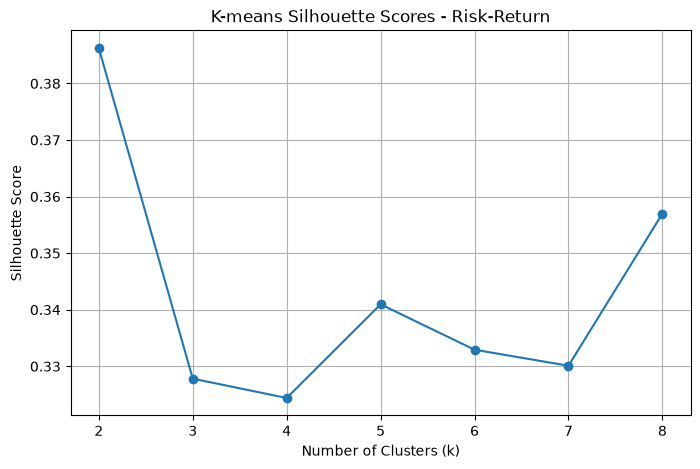

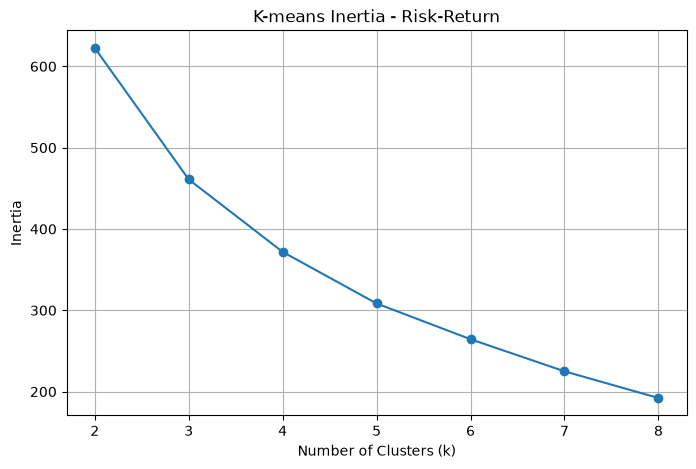

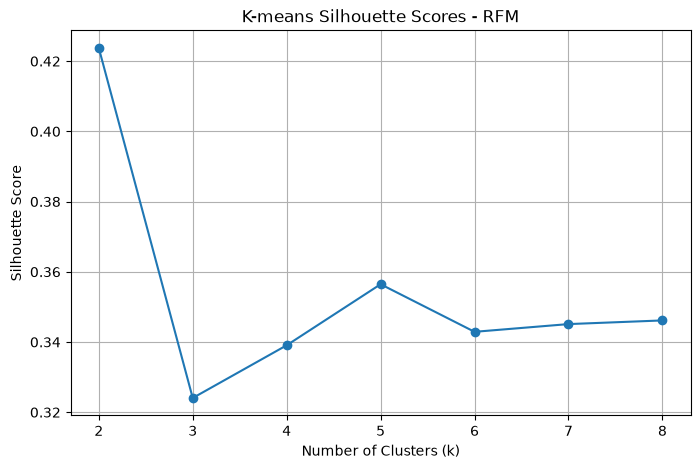

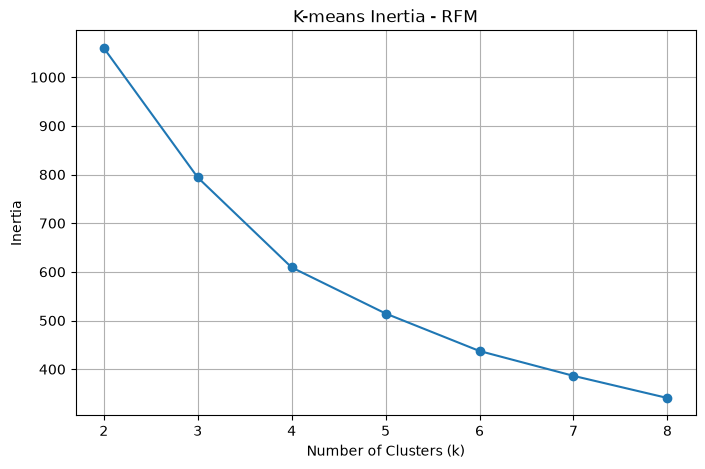

In [148]:
import matplotlib.pyplot as plt

# Risk-return silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(
    risk_kmeans_df["Number_of_Clusters"],
    risk_kmeans_df["Silhouette_Score"],
    marker="o"
)
plt.title("K-means Silhouette Scores - Risk-Return")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Risk-return inertia
plt.figure(figsize=(8, 5))
plt.plot(
    risk_kmeans_df["Number_of_Clusters"],
    risk_kmeans_df["Inertia"],
    marker="o"
)
plt.title("K-means Inertia - Risk-Return")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# RFM silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(
    rfm_kmeans_df["Number_of_Clusters"],
    rfm_kmeans_df["Silhouette_Score"],
    marker="o"
)
plt.title("K-means Silhouette Scores - RFM")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# RFM inertia
plt.figure(figsize=(8, 5))
plt.plot(
    rfm_kmeans_df["Number_of_Clusters"],
    rfm_kmeans_df["Inertia"],
    marker="o"
)
plt.title("K-means Inertia - RFM")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

# Save the results
risk_kmeans_df.to_csv("risk_return_kmeans_evaluation.csv", index=False)
rfm_kmeans_df.to_csv("rfm_kmeans_evaluation.csv", index=False)

In [149]:
from sklearn.cluster import KMeans
import pandas as pd

# Final risk-return K-means model
risk_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

risk_kmeans_labels = risk_kmeans_final.fit_predict(risk_scaled)

# Final RFM K-means model
rfm_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

rfm_kmeans_labels = rfm_kmeans_final.fit_predict(rfm_scaled)

# Combine all cluster assignments
final_results = pd.DataFrame(index=risk_scaled.index)

final_results["Risk_Return_Ward"] = risk_hierarchical_labels
final_results["Risk_Return_KMeans"] = risk_kmeans_labels
final_results["RFM_Ward"] = rfm_hierarchical_labels
final_results["RFM_KMeans"] = rfm_kmeans_labels

display(final_results.head(10))

# Save results
final_results.to_csv("final_clustering_results.csv")

,Risk_Return_Ward,Risk_Return_KMeans,RFM_Ward,RFM_KMeans
Ticker,,,,
AMP,7,1,0,0
AMZN,1,1,0,0
AMGN,0,0,0,0
ALL,3,0,1,0
ANET,4,1,1,1
T,0,0,0,0
MMM,5,0,0,0
AJG,3,0,0,0
AMCR,0,0,0,0


In [150]:
print("Risk-return K-means cluster sizes:")
print(final_results["Risk_Return_KMeans"].value_counts().sort_index())

print("\nRFM K-means cluster sizes:")
print(final_results["RFM_KMeans"].value_counts().sort_index())

Risk-return K-means cluster sizes:
Risk_Return_KMeans
0    344
1    139
Name: count, dtype: int64

RFM K-means cluster sizes:
RFM_KMeans
0    415
1     68
Name: count, dtype: int64


In [151]:
# Risk-return cluster profiles
risk_profile = risk_return.join(
    final_results["Risk_Return_KMeans"]
).groupby("Risk_Return_KMeans").agg(
    Company_Count=("Mean_Weekly_Return", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean")
)

print("Risk-return K-means profiles:")
display(risk_profile.round(4))


# RFM cluster profiles
rfm_profile = rfm.join(
    final_results["RFM_KMeans"]
).groupby("RFM_KMeans").agg(
    Company_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

print("RFM K-means profiles:")
display(rfm_profile.round(2))

Risk-return K-means profiles:


,Company_Count,Average_Weekly_Return,Average_Beta
Risk_Return_KMeans,,,
0,344,0.0018,0.8177
1,139,0.0053,1.3503


RFM K-means profiles:


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary
RFM_KMeans,,,,
0,415,13.39,3.17,3.169847e+10
1,68,63.34,1.78,7.989639e+10


Examine the hierarchical cluster profile 

In [152]:
# Risk-return Ward cluster profiles
risk_ward_profile = risk_return.join(
    final_results["Risk_Return_Ward"]
).groupby("Risk_Return_Ward").agg(
    Company_Count=("Mean_Weekly_Return", "count"),
    Average_Weekly_Return=("Mean_Weekly_Return", "mean"),
    Average_Beta=("Beta", "mean")
)

print("Risk-return Ward profiles:")
display(risk_ward_profile.round(4))


# RFM Ward cluster profiles
rfm_ward_profile = rfm.join(
    final_results["RFM_Ward"]
).groupby("RFM_Ward").agg(
    Company_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

print("RFM Ward profiles:")
display(rfm_ward_profile.round(2))

Risk-return Ward profiles:


,Company_Count,Average_Weekly_Return,Average_Beta
Risk_Return_Ward,,,
0,113,0.0010,0.5719
1,48,0.0020,1.6280
2,5,0.0129,2.3386
3,97,0.0042,0.7070
4,30,0.0082,1.2681
5,114,0.0020,1.0311
6,22,-0.0016,1.1397
7,54,0.0047,1.2092


RFM Ward profiles:


,Company_Count,Average_Recency,Average_Frequency,Average_Monetary
RFM_Ward,,,,
0,388,12.08,3.19,3.707474e+10
1,95,54.47,2.08,4.424022e+10


RFM sensitivity analysist - remove monetary 

In [153]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# Step 1: Keep Recency and Frequency only
rf_only = rfm[["Recency", "Frequency"]].copy()

# Step 2: Standardise the two remaining features
rf_scaler = StandardScaler()
rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_only),
    index=rf_only.index,
    columns=rf_only.columns
)

# Step 3: Repeat Ward clustering with 2 clusters
rf_ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

rf_ward_labels = rf_ward_model.fit_predict(rf_scaled)

# Step 4: Compare with original RFM Ward labels
ari_score = adjusted_rand_score(
    rfm_hierarchical_labels,
    rf_ward_labels
)

print("Adjusted Rand Index:", round(ari_score, 4))

# Step 5: Check revised cluster sizes
print("\nCluster sizes without Monetary:")
print(pd.Series(rf_ward_labels).value_counts().sort_index())

Adjusted Rand Index: 0.9236

Cluster sizes without Monetary:
0    394
1     89
Name: count, dtype: int64


Examine correlations between RFM features 

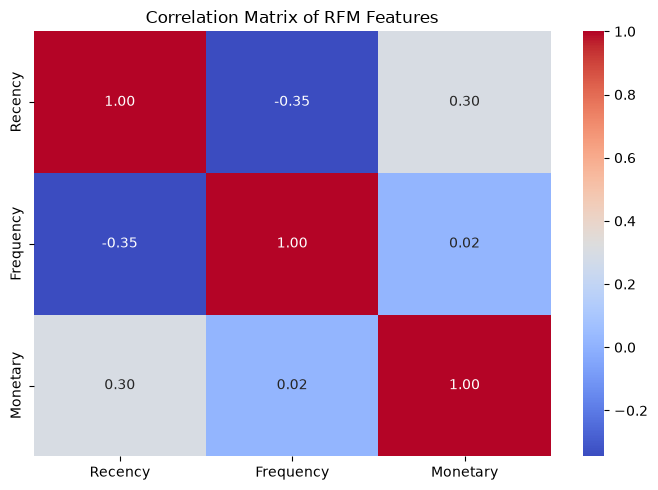

,Recency,Frequency,Monetary
Recency,1.000,-0.345,0.300
Frequency,-0.345,1.000,0.015
Monetary,0.300,0.015,1.000


In [154]:
import seaborn as sns
import matplotlib.pyplot as plt

rfm_correlations = rfm[["Recency", "Frequency", "Monetary"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    rfm_correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of RFM Features")
plt.tight_layout()
plt.show()

display(rfm_correlations.round(3))

In [ ]:
import platform, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, scipy, yfinance
from scipy.stats import skew, kurtosis
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# ---------- Environment and dates ----------
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| yfinance", yfinance.__version__)
print("Date this cell was run:", datetime.date.today())   # use the date you actually downloaded; note it in the report

Python 3.14.0 | pandas 3.1.1 | numpy 2.3.5 | scikit-learn 1.9.1 | scipy 1.18.1 | yfinance 1.8.0
Date this cell was run: 2026-11-22


In [156]:
import pandas as pd

clean_stocks = pd.read_parquet("clean_stocks_488.parquet")

print("Dataset loaded successfully")
print("Shape:", clean_stocks.shape)
display(clean_stocks.head())

Dataset loaded successfully
Shape: (1005, 3864)


Ticker             AMP                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  195.300003  195.899994  185.800003  188.110001  171.959763   
2021-01-05  188.110001  189.850006  185.710007  187.009995  170.954208   
2021-01-06  191.259995  199.940002  190.830002  197.740005  180.763031   
2021-01-07  200.000000  202.179993  199.410004  200.130005  182.947769   
2021-01-08  200.750000  201.639999  198.520004  201.550003  184.245865   

Ticker                                           AMZN              ...  \
Price       Volume Dividends Stock Splits        Open        High  ...   
Date                                                               ...   
2021-01-04  587800       0.0          0.0  163.500000  163.600006  ...   
2021-01-05  560900       0.0          0.0  158.300507  161.169006  ...   
2021-01-06  736400       0.0          0.0  157.324005  159.875504  ...   
2021-01-07  585900       0.0          0.0  157.850006  160.427002  ...   
2021-01-08  545400       0.0          0.0  159.000000  159.531998  ...   

Ticker           ZTS                     ZBRA                          \
Price      Dividends Stock Splits        Open        High         Low   
Date                                                                    
2021-01-04       0.0          0.0  385.750000  387.000000  372.459991   
2021-01-05       0.0          0.0  376.510010  381.809998  374.970001   
2021-01-06       0.0          0.0  377.220001  397.119995  377.220001   
2021-01-07       0.0          0.0  395.899994  411.959991  395.149994   
2021-01-08       0.0          0.0  410.000000  415.450012  404.640015   

Ticker                                                             
Price            Close   Adj Close  Volume Dividends Stock Splits  
Date                                                               
2021-01-04  378.130005  378.130005  432600       0.0          0.0  
2021-01-05  380.570007  380.570007  374700       0.0          0.0  
2021-01-06  394.820007  394.820007  419500       0.0          0.0  
2021-01-07  409.100006  409.100006  379900       0.0          0.0  
2021-01-08  405.470001  405.470001  348500       0.0          0.0  

[5 rows x 3864 columns]

In [ ]:
# ---------- Data validation ----------
import pandas as pd

clean_stocks = pd.read_parquet("clean_stocks_488.parquet")

dup_dates = clean_stocks.index.duplicated().sum()
adj  = clean_stocks.xs("Adj Close", axis=1, level="Price")
cls  = clean_stocks.xs("Close",     axis=1, level="Price")
vol  = clean_stocks.xs("Volume",    axis=1, level="Price")
div  = clean_stocks.xs("Dividends", axis=1, level="Price")
spl  = clean_stocks.xs("Stock Splits", axis=1, level="Price")
print("Duplicate dates:", dup_dates)
print("Missing Close / Adj Close / Volume:", cls.isna().sum().sum(), adj.isna().sum().sum(), vol.isna().sum().sum())
print("Non-positive Close / Adj Close:", (cls <= 0).sum().sum(), (adj <= 0).sum().sum())
print("Zero or negative volume (share-days):", (vol <= 0).sum().sum())
print("Shares with zero-volume days:", list(vol.columns[(vol <= 0).any()]))
print("Shares with a stock split in window:", list(spl.columns[(spl > 0).any()]))
print("Dividend-paying shares:", int((div > 0).any().sum()), "| shares where Close != Adj Close on first date:",
      int((cls.iloc[0] - adj.iloc[0]).abs().gt(1e-6).sum()))
big_moves = (adj.pct_change().abs() > 0.5).sum()
print("Shares with a one-day |return| > 50% (possible unadjusted split):", list(big_moves[big_moves > 0].index))

Duplicate dates: 0
Missing Close / Adj Close / Volume: 0 0 0
Non-positive Close / Adj Close: 0 0
Zero or negative volume (share-days): 451
Shares with zero-volume days: ['FERG', 'SW']
Shares with a stock split in window: ['AMZN', 'ANET', 'T', 'MMM', 'GOOG', 'GOOGL', 'APH', 'AVGO', 'BDX', 'TECH', 'CSX', 'DELL', 'CPRT', 'CSGP', 'DXCM', 'DECK', 'COO', 'CTAS', 'DHR', 'CMG', 'EXC', 'ETR', 'DTE', 'FLEX', 'IBM', 'ILMN', 'FTNT', 'LRCX', 'J', 'ISRG', 'LH', 'IP', 'ODFL', 'MNST', 'NVDA', 'NDAQ', 'MCHP', 'MRK', 'PCAR', 'O', 'PANW', 'RJF', 'SRE', 'SHW', 'SMCI', 'TSLA', 'TPL', 'TSCO', 'WMT', 'WRB', 'WSM', 'ZBH']
Dividend-paying shares: 389 | shares where Close != Adj Close on first date: 395
Shares with a one-day |return| > 50% (possible unadjusted split): ['BE', 'CVNA', 'GL']


In [ ]:
stock_adj = clean_stocks.xs(
    "Adj Close",
    axis=1,
    level="Price"
).copy()

benchmark_raw = pd.read_parquet("sp500_benchmark.parquet")

benchmark_adj = benchmark_raw[
    ("Adj Close", "^GSPC")
].copy()

print("Stock adjusted prices:", stock_adj.shape)
print("Benchmark observations:", benchmark_adj.shape)

# ---------- Exclude incomplete first/final weeks and recompute ----------
sessions_per_week = clean_stocks.index.to_series().resample("W-FRI").count()
print(sessions_per_week.head(2), sessions_per_week.tail(2), sep="\n")
complete_weeks = sessions_per_week.index[:-1] if sessions_per_week.iloc[-1] < 3 else sessions_per_week.index
w_px  = stock_adj.resample("W-FRI").last().loc[complete_weeks]
b_px  = benchmark_adj.resample("W-FRI").last().loc[complete_weeks]
w_ret = w_px.pct_change().dropna()
b_ret = b_px.pct_change().dropna()
assert (w_ret.index == b_ret.index).all()
print("Aligned weekly observations:", len(w_ret))
risk_return_fixed = pd.DataFrame({"Mean_Weekly_Return": w_ret.mean(),
                                  "Beta": w_ret.apply(lambda s: s.cov(b_ret)) / b_ret.var()})
print(risk_return_fixed.describe().round(4))
if "risk_return" in globals():
    print(
        "Max abs change in beta vs notebook version:",
        (risk_return_fixed["Beta"] - risk_return["Beta"]).abs().max()
    )
else:
    print("Original risk_return table is not in memory.")
    print("Using the corrected risk_return_fixed table.")

Stock adjusted prices: (1005, 483)
Benchmark observations: (1005,)
Date
2021-01-08    5
2021-01-15    5
Freq: W-FRI, Name: Date, dtype: int64
Date
2024-12-27    4
2025-01-03    2
Freq: W-FRI, Name: Date, dtype: int64
Aligned weekly observations: 207
       Mean_Weekly_Return      Beta
count            483.0000  483.0000
mean               0.0028    0.9710
std                0.0026    0.4061
min               -0.0045    0.0555
25%                0.0012    0.6663
50%                0.0026    0.9441
75%                0.0042    1.1744
max                0.0178    3.7786
Max abs change in beta vs notebook version: 0.0


In [ ]:
observation_date = clean_stocks.index.max()

latest_60_dates = clean_stocks.index[-60:]

print("Observation date:", observation_date.date())
print("60-session window:", latest_60_dates[0].date(),
      "to", latest_60_dates[-1].date())
print("Number of sessions:", len(latest_60_dates))

# ---------- Worked RFM example ----------
t = "WFC"
v, c = clean_stocks[t]["Volume"], clean_stocks[t]["Close"]
base = v.shift(1).rolling(20).mean()
thr  = 2 * base
flag = v > thr
ex = pd.DataFrame({"Close": c, "Volume": v, "Mean prev 20": base, "Threshold": thr, "High volume": flag})
print(ex.loc[latest_60_dates].query("`High volume`").round(0))
last_evt = flag[flag].index.max()
print("Latest event:", last_evt.date(), "| Recency =", (observation_date - last_evt).days)
print("Frequency (60 sessions) =", int(flag.loc[latest_60_dates].sum()))
print("Monetary = sum(Close*Volume) =", f"{(c.loc[latest_60_dates]*v.loc[latest_60_dates]).sum():,.0f}")
print("Rows with no valid baseline (first 20 sessions):", int(base.isna().sum()))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Number of sessions: 60
            Close    Volume  Mean prev 20   Threshold  High volume
Date                                                              
2024-10-11   61.0  37049200    17133040.0  34266080.0         True
2024-11-06   72.0  63689100    18024830.0  36049660.0         True
2024-12-20   70.0  50113400    16967795.0  33935590.0         True
Latest event: 2024-12-20 | Recency = 11
Frequency (60 sessions) = 3
Monetary = sum(Close*Volume) = 72,701,941,305
Rows with no valid baseline (first 20 sessions): 20


In [ ]:
# ---------- Rebuild RFM features ----------

observation_date = clean_stocks.index.max()

latest_60_dates = clean_stocks.index[-60:]

rfm_rows = []

for ticker in stock_adj.columns:

    close = stock_adj[ticker]
    volume = clean_stocks[(ticker, "Volume")]

    previous_20_avg = volume.shift(1).rolling(20).mean()
    high_volume = volume > (2 * previous_20_avg)

    event_dates = high_volume[high_volume].index

    if len(event_dates) > 0:
        last_event = event_dates.max()
        recency = (observation_date - last_event).days
    else:
        recency = np.nan

    frequency = high_volume.loc[latest_60_dates].sum()

    monetary = (
        close.loc[latest_60_dates] *
        volume.loc[latest_60_dates]
    ).sum()

    rfm_rows.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary
    })

rfm = pd.DataFrame(rfm_rows).set_index("Ticker")

print("RFM shape:", rfm.shape)
rfm.head()

RFM shape: (483, 3)


,Recency,Frequency,Monetary
Ticker,,,
AMP,11,2,1.431339e+10
AMZN,11,5,4.681770e+11
AMGN,11,4,5.320799e+10
ALL,36,3,1.680275e+10
ANET,53,3,4.614568e+10


RFM shape: (483, 3)
(483, 2)
                     skew  excess_kurtosis  max_abs_z
Mean_Weekly_Return   0.89             3.08       5.65
Beta                 1.11             4.53       6.91
Recency              3.63            20.71       9.42
Frequency            0.45             0.60       3.79
Monetary            11.66           154.01      14.00
log1p_M              1.10             2.73       4.86
                     skew  excess_kurtosis  max_abs_z
Mean_Weekly_Return   0.89             3.08       5.65
Beta                 1.11             4.53       6.91
Recency              3.63            20.71       9.42
Frequency            0.45             0.60       3.79
Monetary            11.66           154.01      14.00
log1p_M              1.10             2.73       4.86


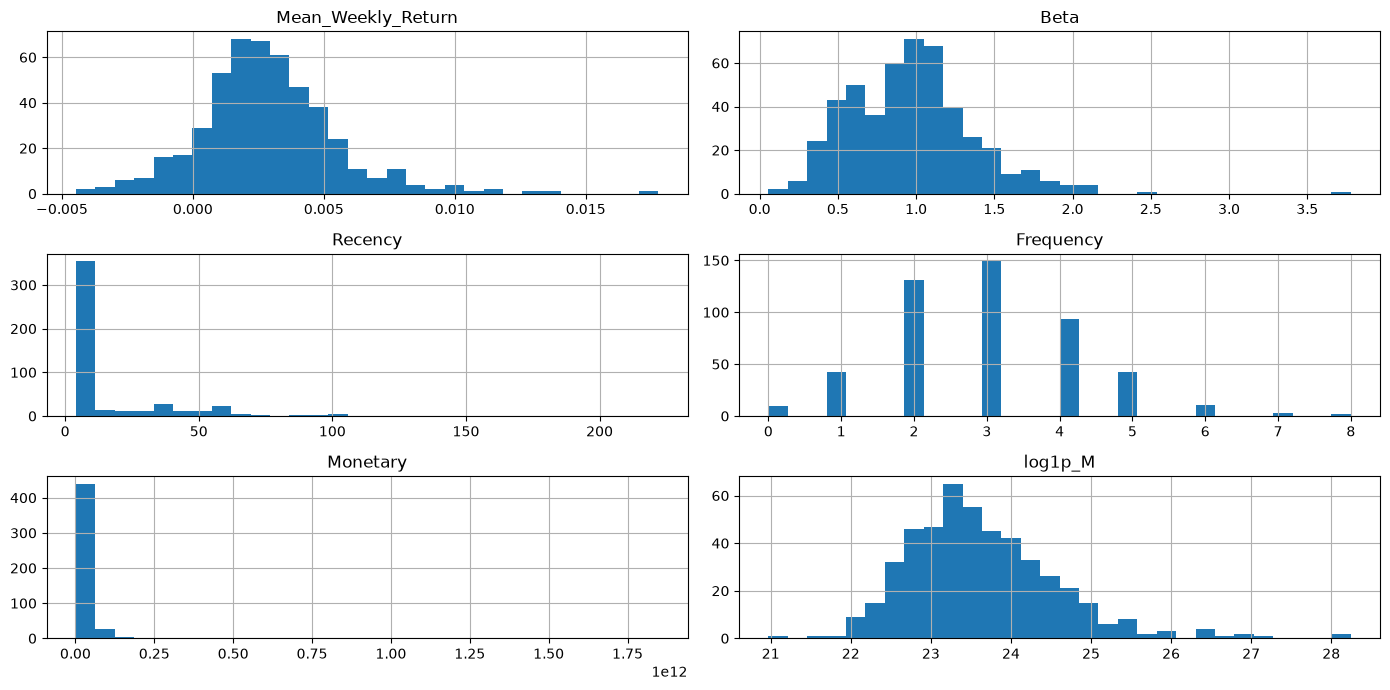

Share of shares with Recency == mode: 0.727 | mode = 11
           Recency  Frequency  log1p_M
Recency      1.000     -0.345    0.152
Frequency   -0.345      1.000    0.013
log1p_M      0.152      0.013    1.000
           Recency  Frequency  log1p_M
Recency      1.000      -0.20    0.131
Frequency   -0.200       1.00   -0.050
log1p_M      0.131      -0.05    1.000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis

observation_date = clean_stocks.index.max()

latest_60_dates = clean_stocks.index[-60:]

rfm_rows = []

for ticker in stock_adj.columns:

    close = stock_adj[ticker]
    volume = clean_stocks[(ticker, "Volume")]

    previous_20_avg = volume.shift(1).rolling(20).mean()
    high_volume = volume > (2 * previous_20_avg)

    event_dates = high_volume[high_volume].index

    if len(event_dates) > 0:
        last_event = event_dates.max()
        recency = (observation_date - last_event).days
    else:
        recency = np.nan

    frequency = high_volume.loc[latest_60_dates].sum()

    monetary = (
        close.loc[latest_60_dates] *
        volume.loc[latest_60_dates]
    ).sum()

    rfm_rows.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary
    })

rfm = pd.DataFrame(rfm_rows).set_index("Ticker")

print("RFM shape:", rfm.shape)
rfm.head()

risk_return = risk_return_fixed.copy()

print(risk_return.shape)

feat = pd.concat([
    risk_return,
    rfm.assign(log1p_M=np.log1p(rfm["Monetary"]))
], axis=1)

summ = pd.DataFrame({
    "skew": feat.apply(skew),
    "excess_kurtosis": feat.apply(kurtosis),
    "max_abs_z": ((feat - feat.mean()) / feat.std()).abs().max()
})

print(summ.round(2))

# ---------- Skew and outliers ----------
feat = pd.concat([risk_return, rfm.assign(log1p_M=np.log1p(rfm["Monetary"]))], axis=1)
summ = pd.DataFrame({"skew": feat.apply(skew), "excess_kurtosis": feat.apply(kurtosis),
                     "max_abs_z": ((feat - feat.mean()) / feat.std()).abs().max()})
print(summ.round(2))
feat.hist(bins=30, figsize=(14, 7)); plt.tight_layout(); plt.show()
print("Share of shares with Recency == mode:", (rfm["Recency"] == rfm["Recency"].mode()[0]).mean().round(3),
      "| mode =", rfm["Recency"].mode()[0])

# ---------- Correlation using log1p(M) as specified ----------
rfm_l = rfm.assign(log1p_M=np.log1p(rfm["Monetary"]))[["Recency", "Frequency", "log1p_M"]]
print(rfm_l.corr().round(3)); print(rfm_l.corr(method="spearman").round(3))

In [ ]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score

# Recreate selected cluster labels

final_results = {}

final_results["Risk_Return_Ward"] = AgglomerativeClustering(
    n_clusters=8, linkage="ward"
).fit_predict(risk_scaled)

final_results["Risk_Return_KMeans"] = KMeans(
    n_clusters=2, random_state=42, n_init=20
).fit_predict(risk_scaled)

final_results["RFM_Ward"] = AgglomerativeClustering(
    n_clusters=2, linkage="ward"
).fit_predict(rfm_scaled)

final_results["RFM_KMeans"] = KMeans(
    n_clusters=2, random_state=42, n_init=20
).fit_predict(rfm_scaled)

# Rebuild scaled feature matrices 

from sklearn.preprocessing import StandardScaler

risk_scaled = StandardScaler().fit_transform(
    risk_return[["Mean_Weekly_Return", "Beta"]]
)

rfm_log = rfm.assign(
    log1p_M=np.log1p(rfm["Monetary"])
)[["Recency", "Frequency", "log1p_M"]]

rfm_scaled = StandardScaler().fit_transform(rfm_log)

print("Risk scaled shape:", risk_scaled.shape)
print("RFM scaled shape:", rfm_scaled.shape)

rows = []
for k in range(2, 9):
    for name, X in [("Risk-return", risk_scaled), ("RFM", rfm_scaled)]:
        w = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        km = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X)
        rows.append({"Matrix": name, "k": k, "ARI_Ward_vs_KMeans": adjusted_rand_score(w, km),
                     "Ward_sizes": sorted(np.bincount(w), reverse=True),
                     "KMeans_sizes": sorted(np.bincount(km), reverse=True)})
cmp_df = pd.DataFrame(rows); print(cmp_df.to_string())
print("Selected solutions:",
      "risk Ward(8) vs KMeans(2) ARI =", round(adjusted_rand_score(final_results["Risk_Return_Ward"], final_results["Risk_Return_KMeans"]), 3),
      "| RFM Ward(2) vs KMeans(2) ARI =", round(adjusted_rand_score(final_results["RFM_Ward"], final_results["RFM_KMeans"]), 3))

Risk scaled shape: (483, 2)
RFM scaled shape: (483, 3)
         Matrix  k  ARI_Ward_vs_KMeans                         Ward_sizes                       KMeans_sizes
0   Risk-return  2            0.104124                         [273, 210]                         [344, 139]
1           RFM  2            0.721105                          [388, 95]                          [415, 68]
2   Risk-return  3            0.608573                     [210, 184, 89]                    [203, 165, 115]
3           RFM  3            0.176348                     [216, 172, 95]                     [269, 150, 64]
4   Risk-return  4            0.450938                 [184, 113, 97, 89]                [164, 147, 131, 41]
5           RFM  4            0.450137                 [172, 144, 95, 72]                 [213, 118, 91, 61]
6   Risk-return  5            0.403926             [136, 113, 97, 89, 48]            [163, 128, 106, 51, 35]
7           RFM  5            0.520135             [172, 144, 83, 72, 12]

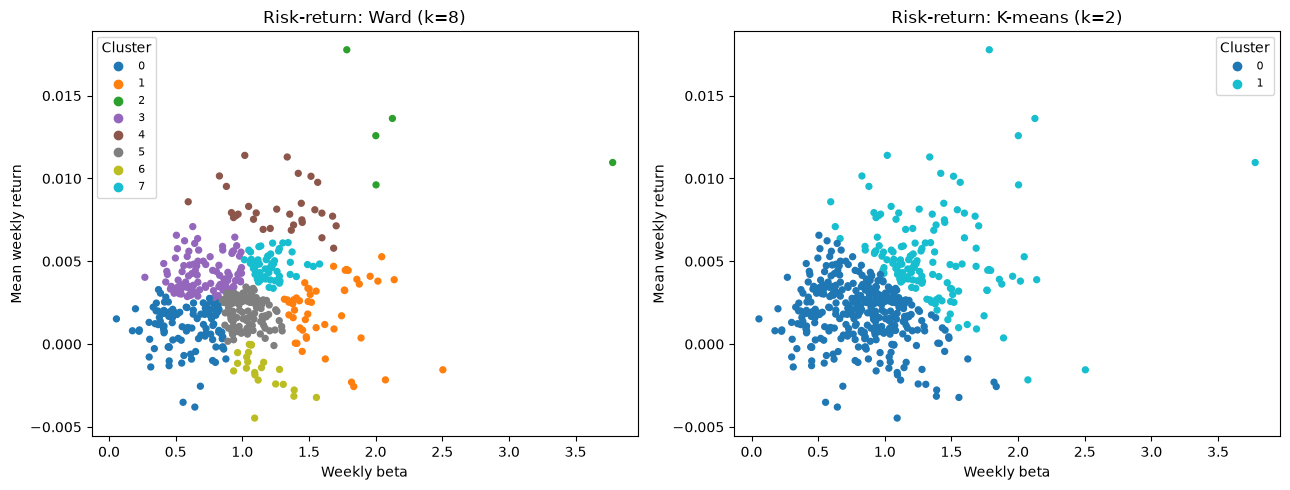

PCA explained variance (RFM): [0.458 0.337] | loadings:
      Recency  Frequency  log1p_M
PC1     0.71      -0.65     0.27
PC2     0.02       0.40     0.91


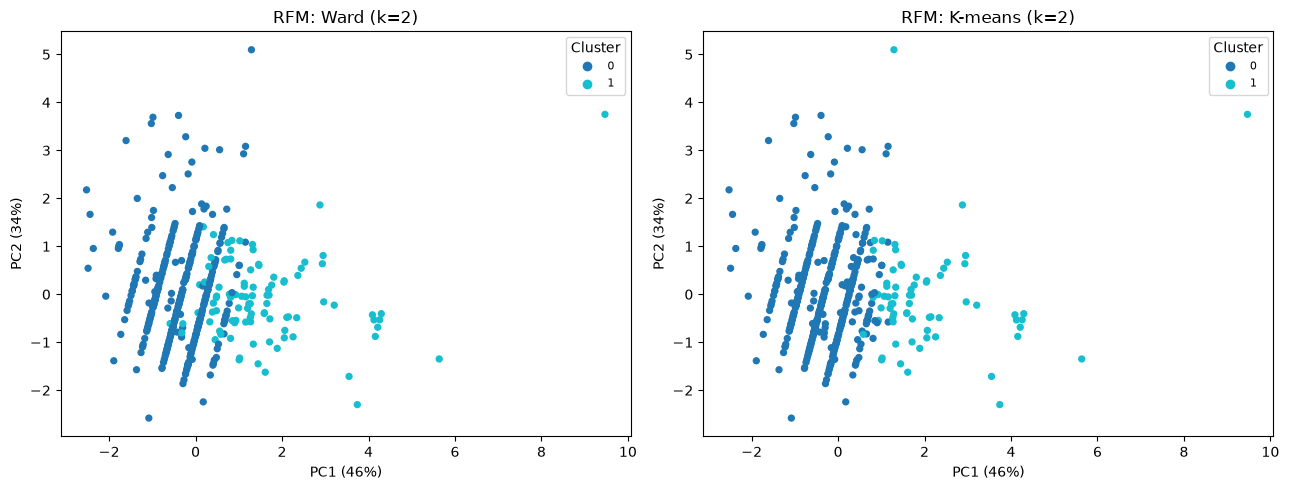

In [ ]:
from sklearn.decomposition import PCA

# ---------- Labelled 2-D visualisations ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, ttl in [(ax[0], "Risk_Return_Ward", "Risk-return: Ward (k=8)"), (ax[1], "Risk_Return_KMeans", "Risk-return: K-means (k=2)")]:
    sc = a.scatter(risk_return["Beta"], risk_return["Mean_Weekly_Return"], c=final_results[col], cmap="tab10", s=18)
    a.set_xlabel("Weekly beta"); a.set_ylabel("Mean weekly return"); a.set_title(ttl)
    a.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()
pca = PCA(n_components=2, random_state=42).fit(rfm_scaled)
Z = pca.transform(rfm_scaled)
print("PCA explained variance (RFM):", pca.explained_variance_ratio_.round(3), "| loadings:\n",
      pd.DataFrame(
       pca.components_,
       columns=["Recency", "Frequency", "log1p_M"],
       index=["PC1", "PC2"]
      ).round(2))     
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, ttl in [(ax[0], "RFM_Ward", "RFM: Ward (k=2)"), (ax[1], "RFM_KMeans", "RFM: K-means (k=2)")]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=final_results[col], cmap="tab10", s=18)
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"); a.set_title(ttl)
    a.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# ---------- Profiles in original units, medians, and R+F-only comparison ----------

rfm_full = rfm.copy()
rfm_full["Daily_traded_value"] = rfm_full["Monetary"] / 60

for col in ["RFM_Ward", "RFM_KMeans"]:
    labels = pd.Series(
        final_results[col],
        index=rfm.index,
        name=col
    )

    print("\n", col)

    profile = rfm_full.join(labels).groupby(col).agg(
        n=("Recency", "size"),
        R_med=("Recency", "median"),
        F_med=("Frequency", "median"),
        M_med=("Monetary", "median"),
        DTV_med=("Daily_traded_value", "median")
    )

    print(profile.round(0))


 RFM_Ward
            n  R_med  F_med         M_med      DTV_med
RFM_Ward                                              
0         388   11.0    3.0  1.498049e+10  249674910.0
1          95   53.0    2.0  2.013167e+10  335527806.0

 RFM_KMeans
              n  R_med  F_med         M_med      DTV_med
RFM_KMeans                                              
0           415   11.0    3.0  1.504389e+10  250731541.0
1            68   55.0    2.0  2.075890e+10  345981707.0


In [ ]:
# ---------- Feature table with cluster assignments ----------
# Recreate R+F-only clustering labels
import os


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
print(os.listdir())
rf_scaled = pd.DataFrame(
    StandardScaler().fit_transform(
        rfm[["Recency", "Frequency"]]
    ),
    index=rfm.index,
    columns=["Recency", "Frequency"]
)

rf_labels = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
).fit_predict(rf_scaled)

print("R+F labels created:", len(rf_labels))

cluster_table = pd.DataFrame(
    {
        name: labels
        for name, labels in final_results.items()
    },
    index=rfm.index
)

cluster_table["RFM_Ward_RF_only"] = rf_labels
sp500 = pd.read_csv("sp500_company_list.csv")
print(sp500.columns.tolist())
sp500.head()

sector_table = sp500.copy()

sector_table["Ticker"] = (
    sector_table["Symbol"]
    .str.replace(".", "-", regex=False)
)

sector_table = sector_table.set_index("Ticker")[
    ["Security", "GICS Sector"]
]

feature_table = (
    risk_return
    .join(rfm)
    .assign(log1p_Monetary=np.log1p(rfm["Monetary"]))
    .join(cluster_table)
    .join(sector_table)
)

feature_table.to_csv("feature_table_with_clusters.csv")

print("Feature table shape:", feature_table.shape)
feature_table.head()

['.git', 'all_stocks_combined.parquet', 'clean_stocks_488.parquet', 'code.ipynb', 'excluded_tickers.csv', 'excluded_tickers_full_report.csv', 'feature_table_with_clusters.csv', 'final_clustering_results.csv', 'hierarchical_clustering_results.csv', 'included_tickers.csv', 'rfm_features.csv', 'rfm_kmeans_evaluation.csv', 'rfm_scaled.csv', 'risk_return_features.csv', 'risk_return_kmeans_evaluation.csv', 'risk_return_scaled.csv', 'sp500_benchmark.parquet', 'sp500_company_list.csv', 'stock_data', 'stock_data_coverage_report.csv']
R+F labels created: 483
['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']
Feature table shape: (483, 13)


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary,log1p_Monetary,Risk_Return_Ward,Risk_Return_KMeans,RFM_Ward,RFM_KMeans,RFM_Ward_RF_only,Security,GICS Sector
Ticker,,,,,,,,,,,,,
AMP,0.005768,1.278280,11,2,1.431339e+10,23.384461,7,1,0,0,0,Ameriprise Financial,Financials
AMZN,0.002681,1.386667,11,5,4.681770e+11,26.872112,1,1,0,0,0,Amazon,Consumer Discretionary
AMGN,0.001596,0.475610,11,4,5.320799e+10,24.697474,0,0,0,0,0,Amgen,Health Care
ALL,0.003865,0.518458,36,3,1.680275e+10,23.544808,3,0,1,0,1,Allstate,Financials
ANET,0.010310,1.419564,53,3,4.614568e+10,24.555069,4,1,1,1,1,Arista Networks,Information Technology


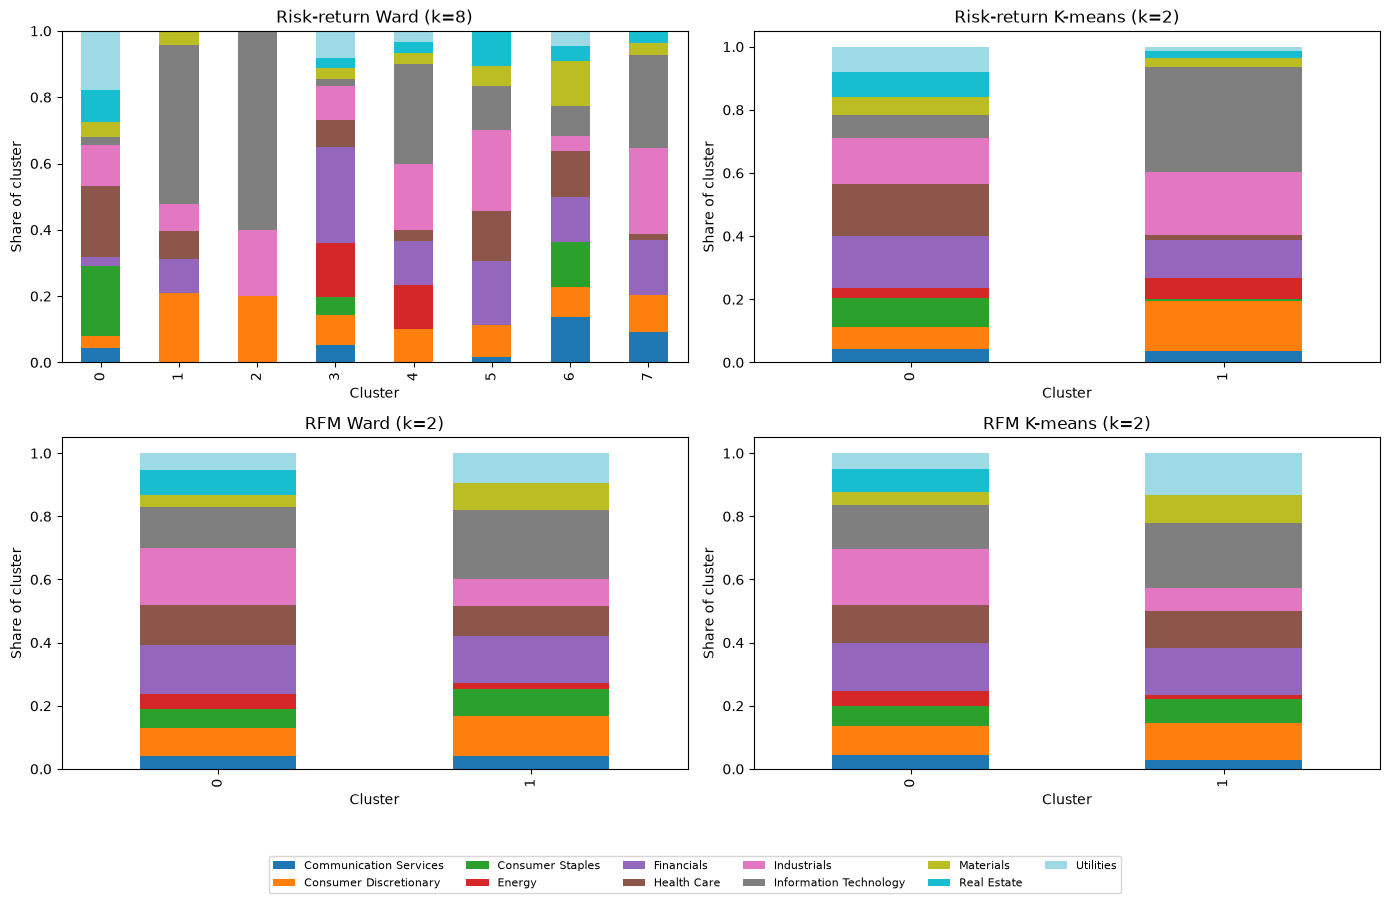

Risk-return Ward (k=8) - sector share relative to base rate (>1 = over-represented)
GICS Sector       Communication Services  Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Utilities
Risk_Return_Ward                                                                                                                                                                           
0                                   1.07                    0.37              3.21    0.00        0.17         1.77         0.77                    0.18       0.93         1.57       2.85
1                                   0.00                    2.19              0.00    0.00        0.68         0.69         0.52                    3.21       0.88         0.00       0.00
2                                   0.00                    2.10              0.00    0.00        0.00         0.00         1.24                    4.02       0.00 

In [ ]:
# ---------- Sector composition and risk-return vs RFM agreement ----------
sol = {"Risk-return Ward (k=8)": "Risk_Return_Ward", "Risk-return K-means (k=2)": "Risk_Return_KMeans",
       "RFM Ward (k=2)": "RFM_Ward", "RFM K-means (k=2)": "RFM_KMeans"}
base = feature_table["GICS Sector"].value_counts(normalize=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (ttl, col) in zip(axes.ravel(), sol.items()):
    ct = pd.crosstab(feature_table[col], feature_table["GICS Sector"], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="tab20")
    ax.set_title(ttl); ax.set_ylabel("Share of cluster"); ax.set_xlabel("Cluster")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8); plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
for ttl, col in sol.items():
    lift = pd.crosstab(feature_table[col], feature_table["GICS Sector"], normalize="index").div(base)
    print(ttl, "- sector share relative to base rate (>1 = over-represented)"); print(lift.round(2).to_string())
print("ARI risk-return K-means vs RFM K-means:", round(adjusted_rand_score(final_results["Risk_Return_KMeans"], final_results["RFM_KMeans"]), 3))
print("ARI risk-return Ward(8) vs RFM Ward(2):", round(adjusted_rand_score(final_results["Risk_Return_Ward"], final_results["RFM_Ward"]), 3))